In [2]:
from google.colab import files

uploaded = files.upload()

import pandas as pd

df = pd.read_csv("daily.csv")
print("First 5 rows:")
print(df.head())

df.head()



Saving daily.csv to daily.csv
First 5 rows:
         date     username  followers                    name   category  \
0  2026-09-25          433   79654283                     433      Media   
1  2026-09-25         9gag   51955772  9GAG: Go Fun The World      Media   
2  2026-09-25        adele   55957481                   Adele      Music   
3  2026-09-25       agustd   55091406         SUGA of BTS 민윤기      Music   
4  2026-09-25  akshaykumar   64955179            Akshay Kumar  Film & TV   

  country    type  rank also_in countries  
0      NL     org    56     NaN        NL  
1      HK     org   133     NaN        HK  
2      GB  person   118     NaN        GB  
3      KR  person   121     NaN        KR  
4      IN  person    88     NaN        IN  


,date,username,followers,name,category,country,type,rank,also_in,countries
0,2026-09-25,433,79654283,433,Media,NL,org,56,NaN,NL
1,2026-09-25,9gag,51955772,9GAG: Go Fun The World,Media,HK,org,133,NaN,HK
2,2026-09-25,adele,55957481,Adele,Music,GB,person,118,NaN,GB
3,2026-09-25,agustd,55091406,SUGA of BTS 민윤기,Music,KR,person,121,NaN,KR
4,2026-09-25,akshaykumar,64955179,Akshay Kumar,Film & TV,IN,person,88,NaN,IN


In [3]:
print("\nRows:", df.shape[0])
print("Columns:", df.shape[1])


Rows: 38071
Columns: 10


In [4]:
print("\nData types:")
print(df.dtypes)


Data types:
date         object
username     object
followers     int64
name         object
category     object
country      object
type         object
rank          int64
also_in      object
countries    object
dtype: object


In [5]:
print("\nMissing values:")
print(df.isna().sum())


Missing values:
date             0
username         0
followers        0
name             0
category         0
country        882
type             0
rank             0
also_in      37024
countries      882
dtype: int64


In [6]:
print("\nMean:")
print(df.mean(numeric_only=True))


Mean:
followers    2.651352e+07
rank         2.630726e+03
dtype: float64


In [7]:
print("\nMedian:")
print(df.median(numeric_only=True))


Median:
followers    11471155.0
rank              981.0
dtype: float64


In [8]:
print("\nMode:")
print(df.mode())


Mode:
          date     username  followers                       name category  \
0   2026-10-02          433        0.0  President Donald J. Trump   Sports   
1          NaN        adele        NaN                        NaN      NaN   
2          NaN  akshaykumar        NaN                        NaN      NaN   
3          NaN   aliaabhatt        NaN                        NaN      NaN   
4          NaN       anitta        NaN                        NaN      NaN   
..         ...          ...        ...                        ...      ...   
95         NaN       vinijr        NaN                        NaN      NaN   
96         NaN  virat.kohli        NaN                        NaN      NaN   
97         NaN    willsmith        NaN                        NaN      NaN   
98         NaN         zara        NaN                        NaN      NaN   
99         NaN      zendaya        NaN                        NaN      NaN   

   country    type  rank    also_in countries  
0       

In [9]:
df.describe()

,followers,rank
count,3.807100e+04,38071.000000
mean,2.651352e+07,2630.725697
std,5.510606e+07,3259.793545
min,0.000000e+00,1.000000
25%,1.375542e+06,307.500000
50%,1.147116e+07,981.000000
75%,2.848081e+07,4207.500000
max,6.866935e+08,11998.000000


In [10]:
print(df.columns.tolist())

['date', 'username', 'followers', 'name', 'category', 'country', 'type', 'rank', 'also_in', 'countries']


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

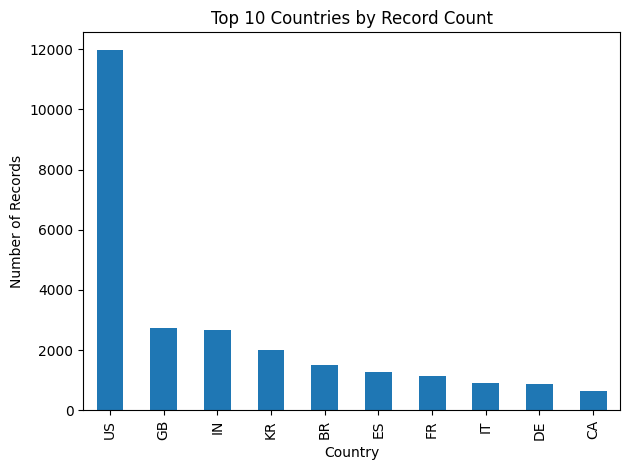

In [12]:
country_counts = df["country"].value_counts().head(10)

country_counts.plot(kind="bar")

plt.title("Top 10 Countries by Record Count")
plt.xlabel("Country")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

In [13]:
numeric_data = df[["followers", "rank"]].copy()

numeric_data["followers"] = pd.to_numeric(
    numeric_data["followers"], errors="coerce"
)

numeric_data["rank"] = pd.to_numeric(
    numeric_data["rank"], errors="coerce"
)

print(numeric_data.notna().sum())

followers    38071
rank         38071
dtype: int64


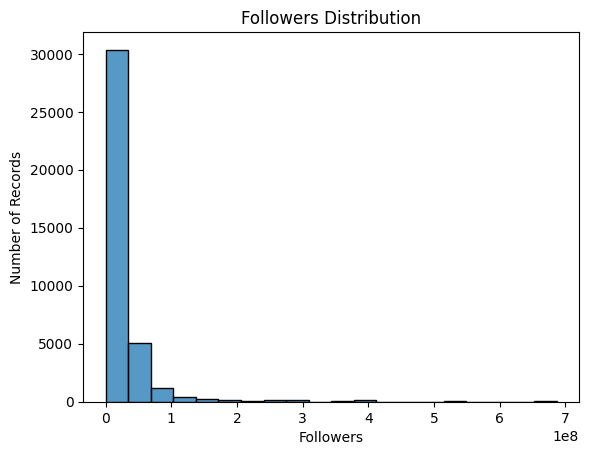

In [14]:
sns.histplot(data=numeric_data, x="followers", bins=20)

plt.title("Followers Distribution")
plt.xlabel("Followers")
plt.ylabel("Number of Records")
plt.show()

In [15]:
clean_df = df.copy()


In [16]:
clean_df.columns = (
    clean_df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

print(clean_df.columns.tolist())

['date', 'username', 'followers', 'name', 'category', 'country', 'type', 'rank', 'also_in', 'countries']


In [17]:
text_columns = clean_df.select_dtypes(
    include=["object", "string"]
).columns

for column in text_columns:
    clean_df[column] = clean_df[column].str.strip()
    clean_df[text_columns] = clean_df[text_columns].replace("", pd.NA)

In [18]:
print("Missing values:")
print(clean_df.isna().sum())

print("\nData types:")
print(clean_df.dtypes)

print("\nDuplicate rows:")
print(clean_df.duplicated().sum())

display(clean_df.head())

Missing values:
date             0
username         0
followers        0
name             0
category         0
country        882
type             0
rank             0
also_in      37024
countries      882
dtype: int64

Data types:
date         object
username     object
followers     int64
name         object
category     object
country      object
type         object
rank          int64
also_in      object
countries    object
dtype: object

Duplicate rows:
0


,date,username,followers,name,category,country,type,rank,also_in,countries
0,2026-09-25,433,79654283,433,Media,NL,org,56,NaN,NL
1,2026-09-25,9gag,51955772,9GAG: Go Fun The World,Media,HK,org,133,NaN,HK
2,2026-09-25,adele,55957481,Adele,Music,GB,person,118,NaN,GB
3,2026-09-25,agustd,55091406,SUGA of BTS 민윤기,Music,KR,person,121,NaN,KR
4,2026-09-25,akshaykumar,64955179,Akshay Kumar,Film & TV,IN,person,88,NaN,IN


In [19]:
clean_df["country"] = clean_df["country"].fillna("Unknown")

print(clean_df["country"].isna().sum())

0


In [20]:
print("Date examples:")
print(clean_df["date"].head())

print("\nCountries examples:")
print(clean_df["countries"].dropna().head())

print("\nAlso_in examples:")
print(clean_df["also_in"].dropna().head())

Date examples:
0    2026-09-25
1    2026-09-25
2    2026-09-25
3    2026-09-25
4    2026-09-25
Name: date, dtype: object

Countries examples:
0    NL
1    HK
2    GB
3    KR
4    IN
Name: countries, dtype: object

Also_in examples:
9            Film & TV
11    Fashion & beauty
20           Film & TV
30           Film & TV
55           Film & TV
Name: also_in, dtype: object


In [21]:
clean_df["date"] = pd.to_datetime(
    clean_df["date"],
    format="%Y-%m-%d"
)

print(clean_df["date"].dtype)

clean_df["countries"] = clean_df["countries"].fillna("Unknown")
clean_df["also_in"] = clean_df["also_in"].fillna("Not specified")

print(clean_df.isna().sum())

datetime64[ns]
date         0
username     0
followers    0
name         0
category     0
country      0
type         0
rank         0
also_in      0
countries    0
dtype: int64


In [22]:
clean_df.to_csv("cleaned_daily.csv", index=False)

In [23]:
from google.colab import files

files.download("cleaned_daily.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>